# AML treatment pilot: abundance, state association and reach

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
import scCS

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Biological question and data
How do descriptive state-association scores change after venetoclax plus azacitidine, and how does this compare with observed cell abundance? We use GSE116481, with velocity counts reconstructed by Ranek and colleagues ([Zenodo 6587903](https://doi.org/10.5281/zenodo.6587903)). Both `spliced` and `unspliced` layers are checked and the loom checksum is verified.

**This is one patient, not a replicated treatment experiment.** The original annotation combines blasts and immature erythroid cells. There is no per-cell malignant genotype here. The selected outcomes are annotation-defined monocytic and erythroid states; their reach must not be presented as proven differentiation of malignant blasts. Day 4 has only five annotated root cells, so the scoring comparison is prespecified as baseline versus day 2. No treatment p-value or biological-replicate confidence interval is reported.

A (sample, barcode) join prevents repeated barcode sequences from being matched across time points. The graph is fitted within the prespecified myeloid/erythroid compartment, retaining macrophages as an unselected population. We use deterministic scVelo and a predefined marker-maturation ordering; neither provides clonal ground truth.


In [3]:
from benchmarks.validation import aml

a, composition = aml.prepare(DATA)
display(composition)
print(a)
summary, results, inference_error = aml.compare(a)
display(summary)
print("Formal inference correctly refused:", inference_error)
summary.to_csv(OUT / "aml_treatment_pilot.csv", index=False)

Filtered out 172 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:00) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
AnnData object with n_obs × n_vars = 1186 × 1834
    obs: 'nGene', 'nUMI', 'sample', 'cluster', 'cell_type', 'tSNE_1', 'tSNE_2', 'patient', 'clusters', 'condition', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'marker_maturation'
    var: 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'log1p', 'pca', 'neighbors', 'velocity_params', 'velocity_graph', 'velocity_graph_neg'
   

sample,day0,day2,day4
cell_type,,,
B-Cells (IgA),17,8,10
B-Cells (IgD),122,60,58
Blasts and Immature Eryth,654,146,5
CD4 T cells,395,111,162
CD8 T cells,581,257,286
Early Erythroids,29,8,0
Macrophages,13,5,3
Mature Erythroids,12,2,1
Megakaryocytes,36,5,10


,scope,condition,n_root_cells,biological_replicates,defined_fraction,DFR,UFP,CFA_Monocytic,CFA_Erythroid
0,pooled,day0,654,1,0.033639,0.020113,0.979887,1.0,0.0
1,pooled,day2,146,1,0.013699,0.010874,0.989126,1.0,0.0
2,condition,day0,654,1,0.033639,0.020322,0.979678,1.0,0.0
3,condition,day2,146,1,0.013699,0.010363,0.989637,1.0,0.0


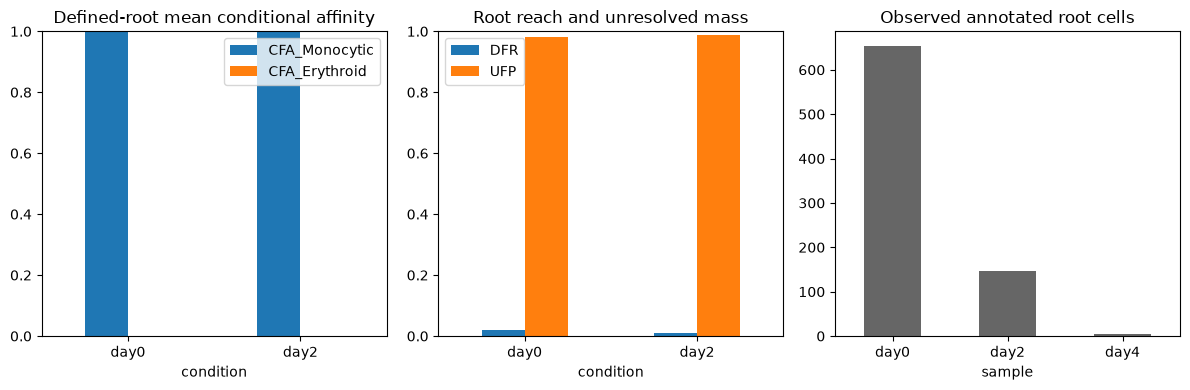

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
selected = summary[summary.scope == "pooled"].set_index("condition")
selected[["CFA_Monocytic", "CFA_Erythroid"]].plot.bar(ax=axes[0], ylim=(0, 1))
selected[["DFR", "UFP"]].plot.bar(ax=axes[1], ylim=(0, 1))
composition.loc["Blasts and Immature Eryth"].plot.bar(ax=axes[2], color="0.4")
axes[0].set_title("Defined-root mean conditional affinity")
axes[1].set_title("Root reach and unresolved mass")
axes[2].set_title("Observed annotated root cells")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## Graph-scope sensitivity and interpretation
The table includes a pooled graph and a graph with cross-condition edges removed, using the same anchor definition. Blocking edges can make some anchors unreachable, so a reach decrease is not automatically evidence of treatment-induced arrest. This comparison exposes dependence on cross-condition borrowing.

Cell counts reflect recovery and sampling as well as biology. CFA is conditional on selected-fate reach, and low reach can reflect finite horizon, missing states, graph errors or genuine arrest. The mixed root annotation and single-patient design prevent causal or population-level conclusions. This pilot is an example of an audited workflow, not the manuscript's definitive tumor-differentiation validation.

In the recorded run, only about 1–3% of root cells have defined selected-fate affinity. The conditional CFA values therefore summarize a small selected subset, not the whole root population. This dataset/settings combination does **not** support a robust differentiation-redirection claim.


In [5]:
assert set(summary.condition) == {"day0", "day2"}
assert summary.biological_replicates.eq(1).all()
assert summary.n_root_cells.min() >= 5
assert inference_error
assert summary[["DFR", "UFP", "defined_fraction"]].ge(0).all().all()
print("Identity alignment, descriptive-design and probability checks passed.")

Identity alignment, descriptive-design and probability checks passed.
